In [ ]:
!zip -r resunet_swinseg_mod_3_outputs.zip /content/resunet_swinseg_mod3_learnablekernel_outputs

  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/ (stored 0%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/training_loss.png (deflated 21%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/test_predicted_masks/ (stored 0%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/test_predicted_masks/image14_prediction.png (deflated 12%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/test_predicted_masks/image7_prediction.png (deflated 9%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/test_predicted_masks/image10_prediction.png (deflated 10%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/dataset_split_manifest.csv (deflated 85%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/validation_metrics_summary.png (deflated 21%)
  adding: content/drive/MyDrive/resunet_mod3_learnablekernel_outputs/training_iou.png (deflated 11%)
  ad

In [2]:
!unzip -q /content/swinseg.zip -d /content/

TensorFlow: 2.21.0
Visible GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Total paired samples: 115
Image: 001.jpg
Mask:  001_GT.jpg

Image: 002.jpg
Mask:  002_GT.jpg

Image: 003.jpg
Mask:  003_GT.jpg

Image: 004.jpg
Mask:  004_GT.jpg

Image: 005.jpg
Mask:  005_GT.jpg

Total paired images: 115
Train: 80 (69.6%)
Validation: 17 (14.8%)
Test: 18 (15.7%)
Saved split manifest: /content/resunet_swinseg_mod3_learnablekernel_outputs/dataset_split_manifest.csv


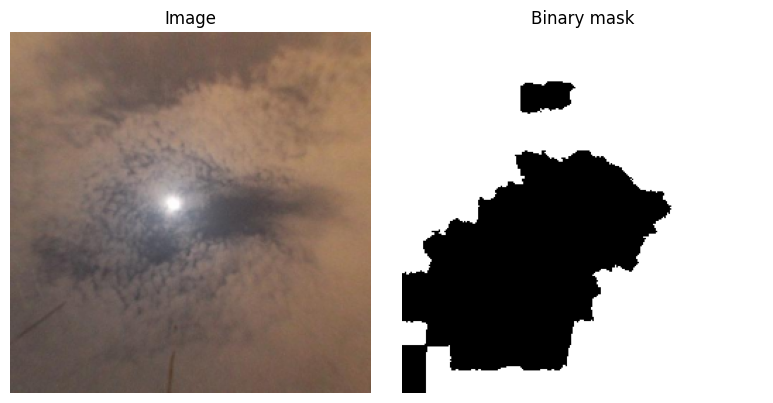

In [3]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from google.colab import drive


SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
TEST_SIZE = 0.30
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5

DRIVE_ROOT = Path("/content/")
DATA_ROOT = DRIVE_ROOT
IMAGE_DIR = DATA_ROOT / "swinseg" / "images"
MASK_DIR = DATA_ROOT / "swinseg" / "GTmaps"
ZIP_PATH = DRIVE_ROOT / "swinseg.zip"
EXTRACT_DIR = Path("/content/swinseg")
OUTPUT_DIR = DRIVE_ROOT / "resunet_swinseg_mod3_learnablekernel_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

tf.keras.utils.set_random_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
print('TensorFlow:', tf.__version__)
print('Visible GPU(s):', tf.config.list_physical_devices('GPU'))

for directory, label in ((IMAGE_DIR, 'IMAGE_DIR'), (MASK_DIR, 'MASK_DIR')):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f'{label} does not exist: {directory}. Update the path in this cell.')

VALID_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
AUTOTUNE = tf.data.AUTOTUNE

def list_image_files(directory):
    return sorted(str(p) for p in Path(directory).iterdir() if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)

def get_pairs(image_dir, mask_dir):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    image_paths = sorted(
        os.path.join(image_dir, name)
        for name in os.listdir(image_dir)
        if os.path.splitext(name)[1].lower() in valid_exts
    )

    # Map masks using their corresponding image filename
    mask_map = {}

    for name in os.listdir(mask_dir):
        ext = os.path.splitext(name)[1].lower()

        if ext not in valid_exts:
            continue

        stem = os.path.splitext(name)[0]

        # Convert 001_GT to 001
        if stem.lower().endswith("_gt"):
            stem = stem[:-3]

        stem = stem.lower()
        mask_map[stem] = os.path.join(mask_dir, name)

    pairs = []

    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0].lower()

        if stem in mask_map:
            pairs.append((img_path, mask_map[stem]))
        else:
            print(f"Warning: no mask found for {img_path}")

    return pairs


pairs = get_pairs(IMAGE_DIR, MASK_DIR)

print("Total paired samples:", len(pairs))

for img, mask in pairs[:5]:
    print("Image:", os.path.basename(img))
    print("Mask: ", os.path.basename(mask))
    print()

def path_text(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    if isinstance(path, (bytes, np.bytes_)):
        return path.decode('utf-8')
    return os.fspath(path)

def load_image_mask(img_path, mask_path):
    img_path = path_text(img_path)
    mask_path = path_text(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f'Could not read image: {img_path}')
    if mask is None:
        raise ValueError(f'Could not read mask: {mask_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    return image, (mask > 127).astype(np.float32)[..., np.newaxis]

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(load_image_mask, [img_path, mask_path], [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_left_right(image), tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_up_down(image), tf.image.flip_up_down(mask)
    return image, mask

def make_dataset(sample_pairs, training=False):
    image_paths = [p[0] for p in sample_pairs]
    mask_paths = [p[1] for p in sample_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(len(sample_pairs), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).batch(BATCH_SIZE).prefetch(AUTOTUNE)

pairs = get_pairs(IMAGE_DIR, MASK_DIR)
train_pairs, holdout_pairs = train_test_split(pairs, test_size=0.30, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(holdout_pairs, test_size=0.50, random_state=SEED, shuffle=True)

sample_keys = lambda records: {Path(image_path).stem.lower() for image_path, _ in records}
train_keys, val_keys, test_keys = map(sample_keys, (train_pairs, val_pairs, test_pairs))
all_keys = sample_keys(pairs)
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
assert len(train_pairs) + len(val_pairs) + len(test_pairs) == len(pairs)
assert train_keys | val_keys | test_keys == all_keys
assert len(all_keys) == len(pairs)

manifest_rows = []
for split_name, split_pairs in (('train', train_pairs), ('validation', val_pairs), ('test', test_pairs)):
    for image_path, mask_path in split_pairs:
        manifest_rows.append({'split': split_name, 'image_path': image_path, 'mask_path': mask_path, 'image_name': Path(image_path).name})
manifest_path = os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv')
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)
train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)

print(f'Total paired images: {len(pairs)}')
print(f'Train: {len(train_pairs)} ({len(train_pairs) / len(pairs):.1%})')
print(f'Validation: {len(val_pairs)} ({len(val_pairs) / len(pairs):.1%})')
print(f'Test: {len(test_pairs)} ({len(test_pairs) / len(pairs):.1%})')
print('Saved split manifest:', manifest_path)
example_image, example_mask = load_image_mask(*train_pairs[0])
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(example_image)
axes[0].set_title('Image')
axes[1].imshow(example_mask[..., 0], cmap='gray')
axes[1].set_title('Binary mask')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
def residual_block_initial(x, filters, strides=(1, 1), name="res_initial"):
    """First residual block: Conv-BN-ReLU-Conv plus a projected shortcut."""
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(x)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)
    shortcut = tf.keras.layers.Conv2D(
        filters, 1, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
    )(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])


def residual_block(x, filters, strides=(1, 1), name="res_block"):
    """Pre-activation residual block with a projection when shape/channels differ."""
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn1")(x)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu1")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[0], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv1"
    )(y)
    y = tf.keras.layers.BatchNormalization(name=f"{name}_bn2")(y)
    y = tf.keras.layers.Activation("relu", name=f"{name}_relu2")(y)
    y = tf.keras.layers.Conv2D(
        filters, 3, strides=strides[1], padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_conv2"
    )(y)

    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(
            filters, 1, strides=strides[0], padding="same", use_bias=False,
            kernel_initializer="he_normal", name=f"{name}_shortcut_conv"
        )(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    else:
        shortcut = x

    return tf.keras.layers.Add(name=f"{name}_add")([shortcut, y])


@tf.keras.utils.register_keras_serializable(package="RockSegmentation")
class LearnableKernelLayer(tf.keras.layers.Layer):
    """Depthwise Sobel-X, Sobel-Y and Laplacian kernels initialized from classical filters.

    Unlike the fixed-kernel variant, this layer's kernel weights are trainable.
    Input:  [B, H, W, C]
    Output: [B, H, W, 3C]
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        channels = int(input_shape[-1])
        sobel_x = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)
        sobel_y = np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=np.float32)
        laplacian = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)



        init_kernel = np.zeros((3, 3, channels, 3), dtype=np.float32)
        for channel in range(channels):
            init_kernel[:, :, channel, 0] = sobel_x
            init_kernel[:, :, channel, 1] = sobel_y
            init_kernel[:, :, channel, 2] = laplacian

        self.kernel = self.add_weight(
            name="kernel",
            shape=(3, 3, channels, 3),
            initializer=tf.keras.initializers.Constant(init_kernel),
            trainable=True
        )
        super().build(input_shape)

    def call(self, x):
        return tf.nn.depthwise_conv2d(
            x,
            self.kernel,
            strides=[1, 1, 1, 1],
            padding="SAME"
        )

    def get_config(self):
        return super().get_config()


def merge_with_learnable_kernels(feat, filters, prefix):
    """Fuse raw encoder features with trainable edge responses; compress to filters."""
    learned_response = LearnableKernelLayer(name=f"{prefix}_learnable_kernel")(feat)
    merged = tf.keras.layers.Concatenate(name=f"{prefix}_raw_learnable_concat")(
        [feat, learned_response]
    )
    merged = tf.keras.layers.Conv2D(
        filters, 1, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{prefix}_compress"
    )(merged)
    merged = tf.keras.layers.ReLU(name=f"{prefix}_compress_relu")(merged)
    return merged


def learnable_kernel_decoder_block(x, skip, skip_learnable, filters, name):
    """Upsample decoder and fuse [decoder, raw encoder skip, learned-kernel skip]."""
    x = tf.keras.layers.UpSampling2D(
        size=(2, 2), interpolation="bilinear", name=f"{name}_upsample"
    )(x)
    x = tf.keras.layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal", name=f"{name}_up_projection"
    )(x)
    x = tf.keras.layers.Concatenate(name=f"{name}_raw_learnable_concat")(
        [x, skip, skip_learnable]
    )
    return residual_block(x, filters, name=f"{name}_residual")


def build_resunet_learnablekernel(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    """ResUNet with learnable Sobel/Laplacian-initialized skip branches only."""
    inputs = tf.keras.Input(shape=input_shape, name="image")


    e0 = residual_block_initial(inputs, filters[0], name="encoder_block0")
    e1 = residual_block(e0, filters[1], strides=(2, 1), name="encoder_block1")
    e2 = residual_block(e1, filters[2], strides=(2, 1), name="encoder_block2")
    e3 = residual_block(e2, filters[3], strides=(2, 1), name="encoder_block3")


    e0_learnable = merge_with_learnable_kernels(e0, filters[0], "skip_e0")
    e1_learnable = merge_with_learnable_kernels(e1, filters[1], "skip_e1")
    e2_learnable = merge_with_learnable_kernels(e2, filters[2], "skip_e2")
    e3_learnable = merge_with_learnable_kernels(e3, filters[3], "skip_e3")


    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name="bridge")


    d3 = learnable_kernel_decoder_block(bridge, e3, e3_learnable, filters[3], "decoder_block3")
    d2 = learnable_kernel_decoder_block(d3, e2, e2_learnable, filters[2], "decoder_block2")
    d1 = learnable_kernel_decoder_block(d2, e1, e1_learnable, filters[1], "decoder_block1")
    d0 = learnable_kernel_decoder_block(d1, e0, e0_learnable, filters[0], "decoder_block0")

    logits = tf.keras.layers.Conv2D(
        1, 1, padding="same", activation=None, name="segmentation_logits"
    )(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name="ResUNet_LearnableKernel")



def _binary_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return y_true, y_pred


def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))


def dice_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth
    )


def iou_coef_logits(y_true, y_pred, smooth=1e-7):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet_learnablekernel(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    filters=PAPER_FILTERS
)
print("Encoder filters:", PAPER_FILTERS)
print("Bridge filters:", PAPER_FILTERS[-1] * 2)
print("Skip fusion: raw feature + trainable Sobel-X/Sobel-Y/Laplacian-initialized response, compressed by 1x1 conv")
print("Learnable kernels are initialized from Sobel/Laplacian patterns; no additional long multi-skip connections.")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits]
)
model.summary()

Encoder filters: (64, 128, 256, 512)
Bridge filters: 1024
Skip fusion: raw feature + trainable Sobel-X/Sobel-Y/Laplacian-initialized response, compressed by 1x1 conv
Learnable kernels are initialized from Sobel/Laplacian patterns; no additional long multi-skip connections.


Model: "ResUNet_LearnableKernel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 40,838,401 (155.79 MB)

 Trainable params: 40,818,945 (155.71 MB)

 Non-trainable params: 19,456 (76.00 KB)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step - binary_accuracy_logits: 0.7923 - dice_coef_logits: 0.7334 - iou_coef_logits: 0.6310 - loss: 0.4809
Epoch 1: val_dice_coef_logits improved from None to 0.44771, saving model to /content/resunet_swinseg_mod3_learnablekernel_outputs/best_resunet_mod3_learnablekernel.weights.h5

Epoch 1: finished saving model to /content/resunet_swinseg_mod3_learnablekernel_outputs/best_resunet_mod3_learnablekernel.weights.h5
40/40 ━━━━━━━━━━━━━━━━━━━━ 138s 833ms/step - binary_accuracy_logits: 0.8579 - dice_coef_logits: 0.8338 - iou_coef_logits: 0.7389 - loss: 0.3349 - val_binary_accuracy_logits: 0.3644 - val_dice_coef_logits: 0.4477 - val_iou_coef_logits: 0.2941 - val_loss: 1.2056 - learning_rate: 1.0000e-04
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - binary_accuracy_logits: 0.8939 - dice_coef_logits: 0.8772 - iou_coef_logits: 0.7898 - loss: 0.2540
Epoch 2: val_dice_coef_logits improved from 0.44771 to 0.60787, saving model to /content/resune

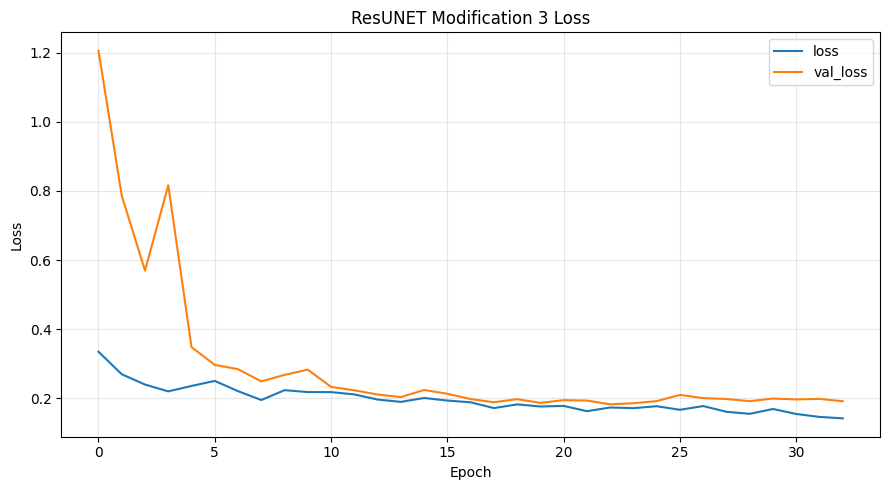

Saved: /content/resunet_swinseg_mod3_learnablekernel_outputs/training_loss.png


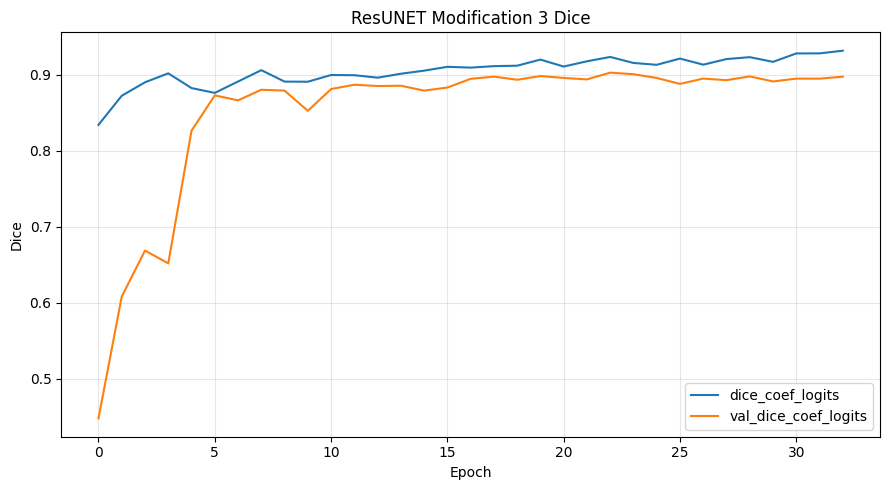

Saved: /content/resunet_swinseg_mod3_learnablekernel_outputs/training_dice.png


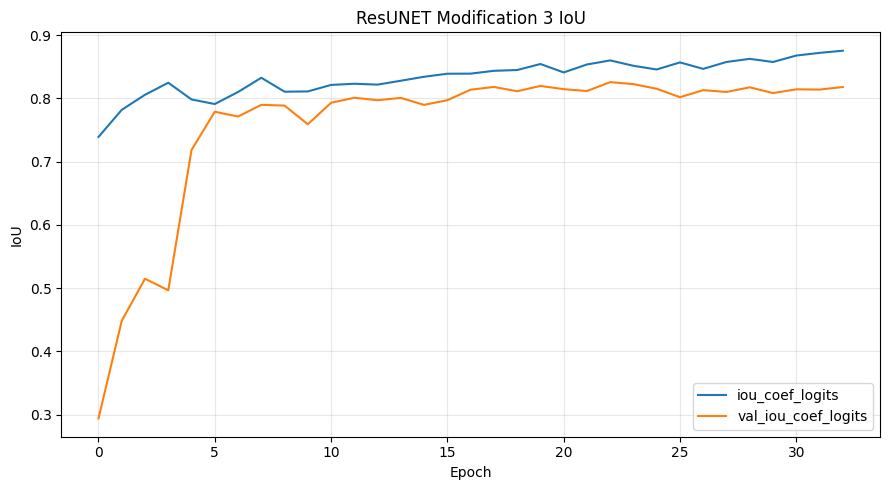

Saved: /content/resunet_swinseg_mod3_learnablekernel_outputs/training_iou.png
Best checkpoint: /content/resunet_swinseg_mod3_learnablekernel_outputs/best_resunet_mod3_learnablekernel.weights.h5
Final inference weights: /content/resunet_swinseg_mod3_learnablekernel_outputs/final_resunet_mod3_learnablekernel.weights.h5
Training history: /content/resunet_swinseg_mod3_learnablekernel_outputs/training_history.csv


In [5]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'best_resunet_mod3_learnablekernel.weights.h5')
FINAL_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'final_resunet_mod3_learnablekernel.weights.h5')

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(filepath=BEST_WEIGHTS_PATH, monitor='val_dice_coef_logits', mode='max', save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_dice_coef_logits', mode='max', patience=10, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_dice_coef_logits', mode='max', factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, 'training_log.csv'))
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
if not os.path.isfile(BEST_WEIGHTS_PATH):
    raise FileNotFoundError(f'Best validation checkpoint was not created: {BEST_WEIGHTS_PATH}')
model.load_weights(BEST_WEIGHTS_PATH)
model.save_weights(FINAL_WEIGHTS_PATH)
history_df = pd.DataFrame(history.history)
history_df.to_csv(os.path.join(OUTPUT_DIR, 'training_history.csv'), index_label='epoch')

for metric_keys, title, ylabel, filename in [
    (('loss', 'val_loss'), 'ResUNET Modification 3 Loss', 'Loss', 'training_loss.png'),
    (('dice_coef_logits', 'val_dice_coef_logits'), 'ResUNET Modification 3 Dice', 'Dice', 'training_dice.png'),
    (('iou_coef_logits', 'val_iou_coef_logits'), 'ResUNET Modification 3 IoU', 'IoU', 'training_iou.png')
]:
    plt.figure(figsize=(9, 5))
    for key in metric_keys:
        if key in history.history:
            plt.plot(history.history[key], label=key)
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plot_path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(plot_path, dpi=160, bbox_inches='tight')
    plt.show()
    print('Saved:', plot_path)

print('Best checkpoint:', BEST_WEIGHTS_PATH)
print('Final inference weights:', FINAL_WEIGHTS_PATH)
print('Training history:', os.path.join(OUTPUT_DIR, 'training_history.csv'))

Validation 1/17: 005.jpg
Validation 2/17: 041.jpg
Validation 3/17: 031.jpg
Validation 4/17: 070.jpg
Validation 5/17: 079.jpg
Validation 6/17: 032.jpg
Validation 7/17: 016.jpg
Validation 8/17: 101.jpg
Validation 9/17: 013.jpg
Validation 10/17: 106.jpg
Validation 11/17: 094.jpg
Validation 12/17: 071.jpg
Validation 13/17: 095.jpg
Validation 14/17: 010.jpg
Validation 15/17: 067.jpg
Validation 16/17: 019.jpg
Validation 17/17: 045.jpg

VALIDATION macro-average metrics
IoU                   : 0.8237 ± 0.1227
Recall                : 0.8945 ± 0.1181
Precision             : 0.9201 ± 0.1013
Dice_Coefficient      : 0.8980 ± 0.0845
Boundary_F1           : 0.5108 ± 0.1748
Boundary_Recall       : 0.5571 ± 0.1732
Boundary_Precision    : 0.4769 ± 0.1792


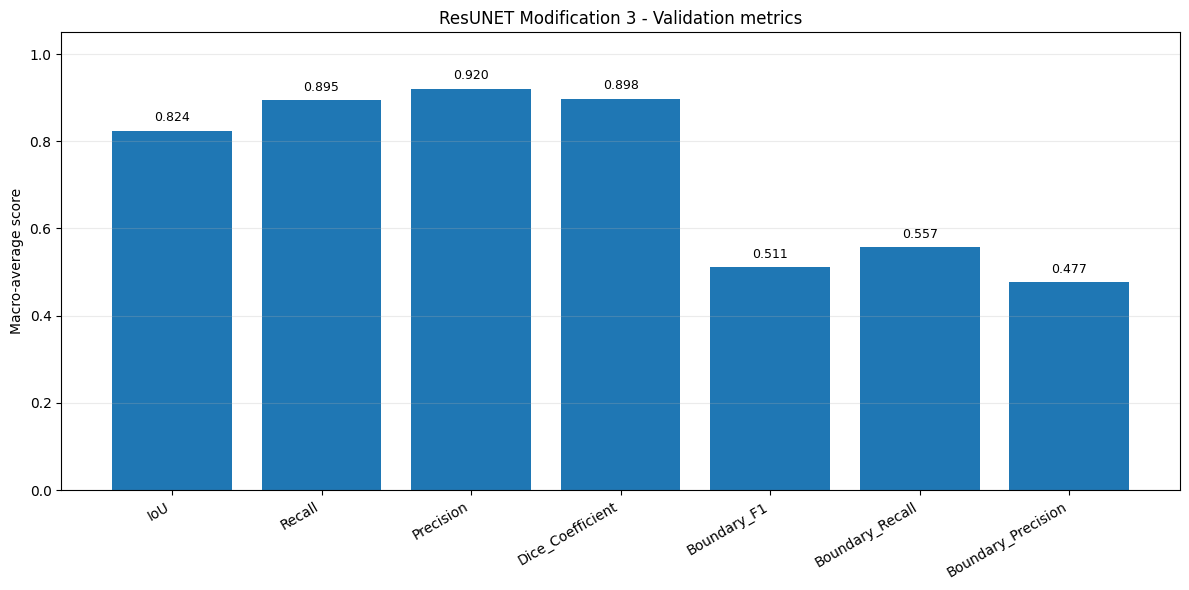

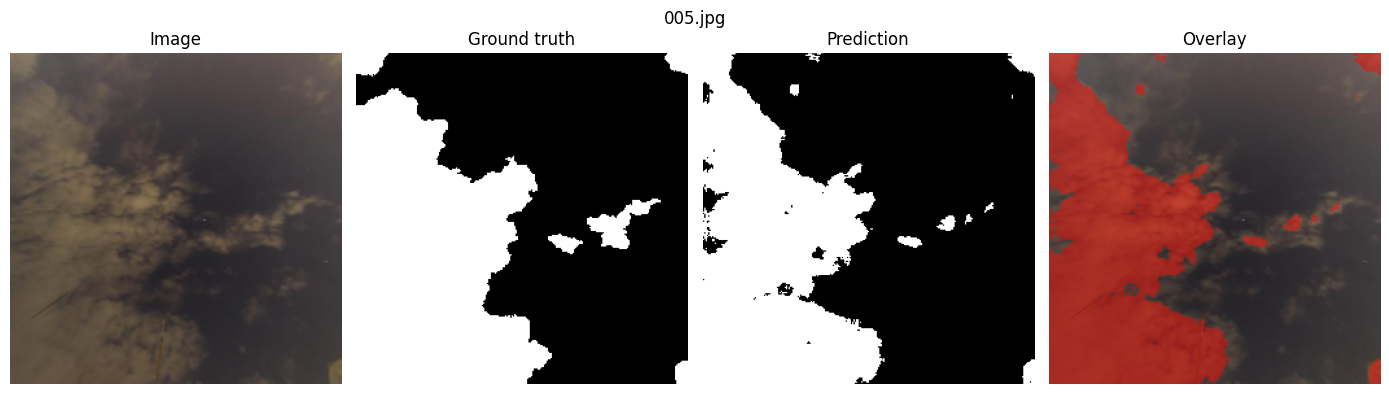

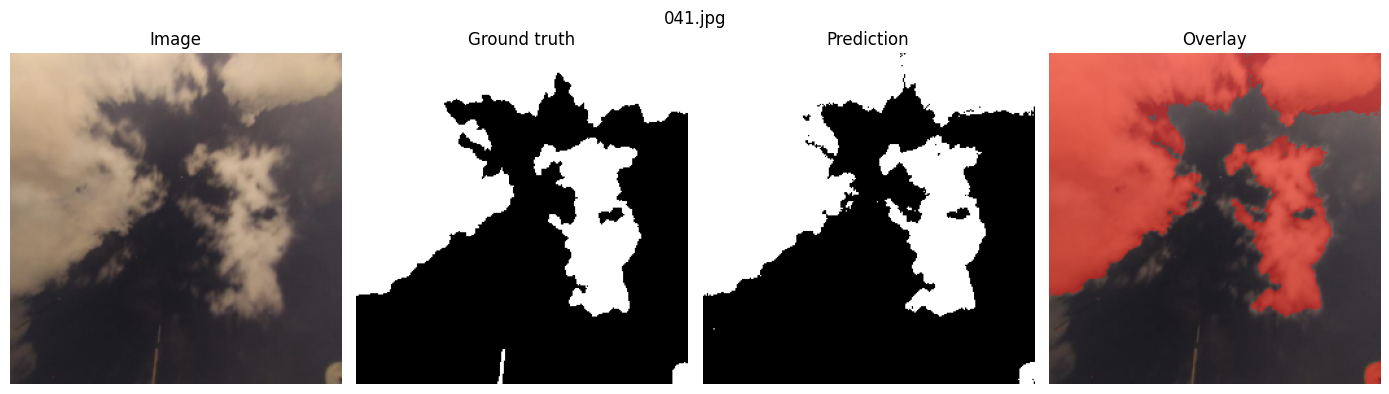

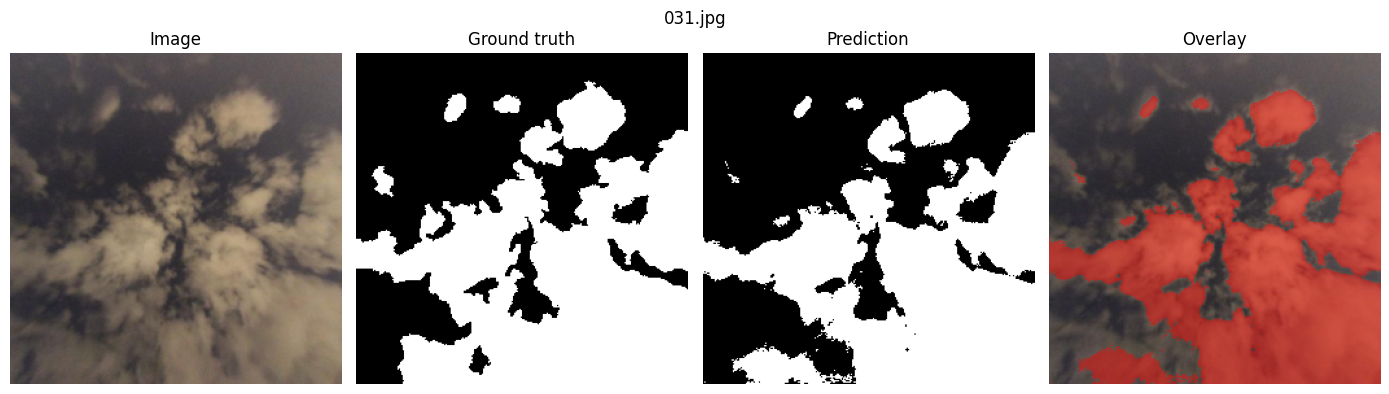

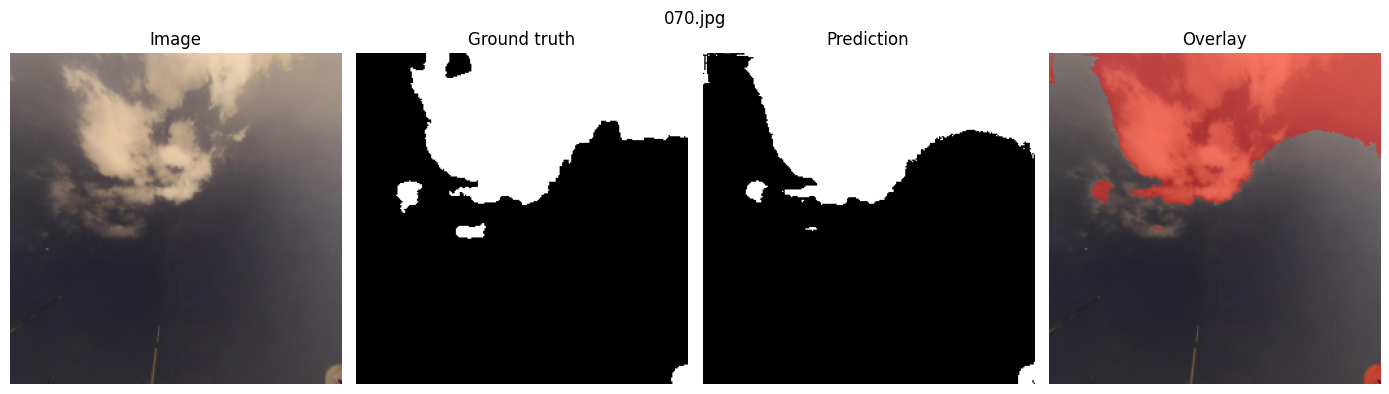

Per-image metrics: /content/resunet_swinseg_mod3_learnablekernel_outputs/validation_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_mod3_learnablekernel_outputs/validation_metrics_summary.csv
Predicted masks: /content/resunet_swinseg_mod3_learnablekernel_outputs/validation_predicted_masks
Comparison previews: /content/resunet_swinseg_mod3_learnablekernel_outputs/validation_previews
Test 1/18: 110.jpg
Test 2/18: 114.jpg
Test 3/18: 068.jpg
Test 4/18: 113.jpg
Test 5/18: 001.jpg
Test 6/18: 109.jpg
Test 7/18: 054.jpg
Test 8/18: 085.jpg
Test 9/18: 048.jpg
Test 10/18: 073.jpg
Test 11/18: 012.jpg
Test 12/18: 084.jpg
Test 13/18: 082.jpg
Test 14/18: 011.jpg
Test 15/18: 027.jpg
Test 16/18: 023.jpg
Test 17/18: 046.jpg
Test 18/18: 037.jpg

TEST macro-average metrics
IoU                   : 0.8076 ± 0.1484
Recall                : 0.8868 ± 0.1683
Precision             : 0.9146 ± 0.0872
Dice_Coefficient      : 0.8854 ± 0.1053
Boundary_F1           : 0.4318 ± 0.1996
Boundary_Recall     

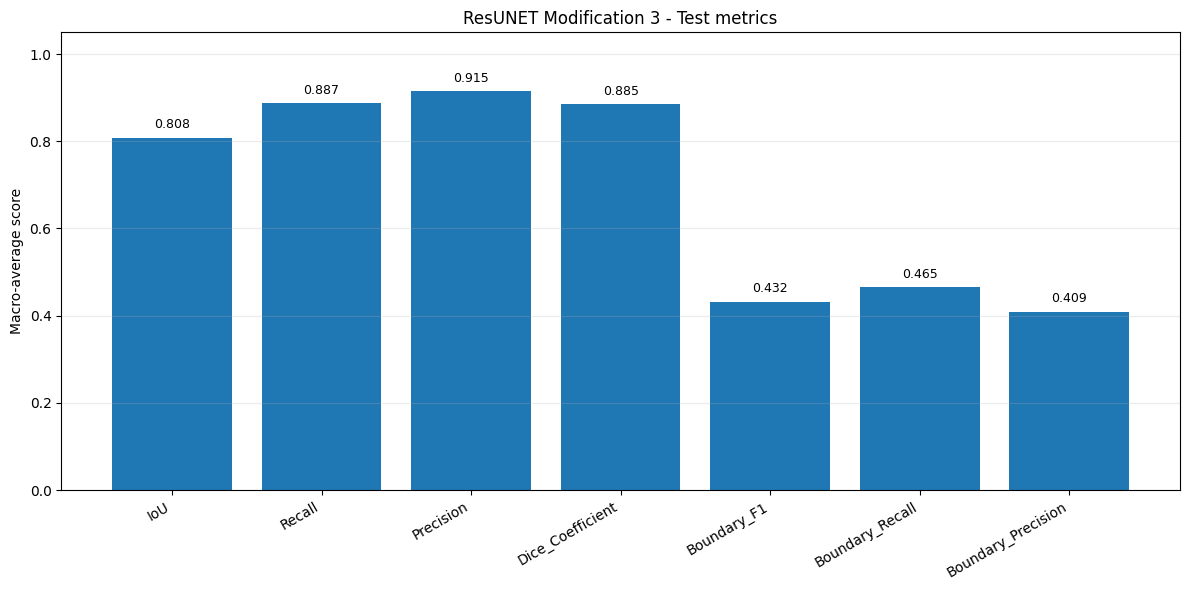

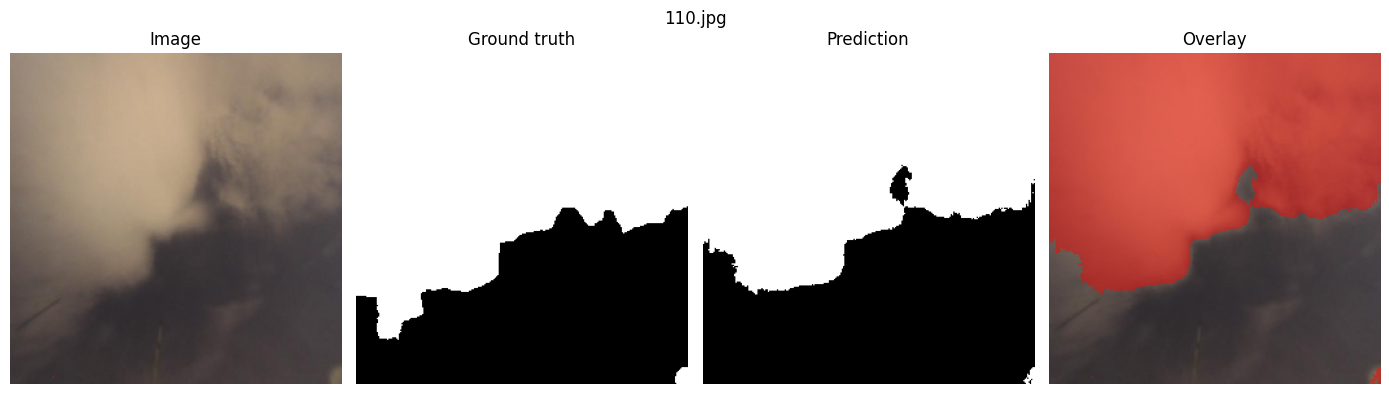

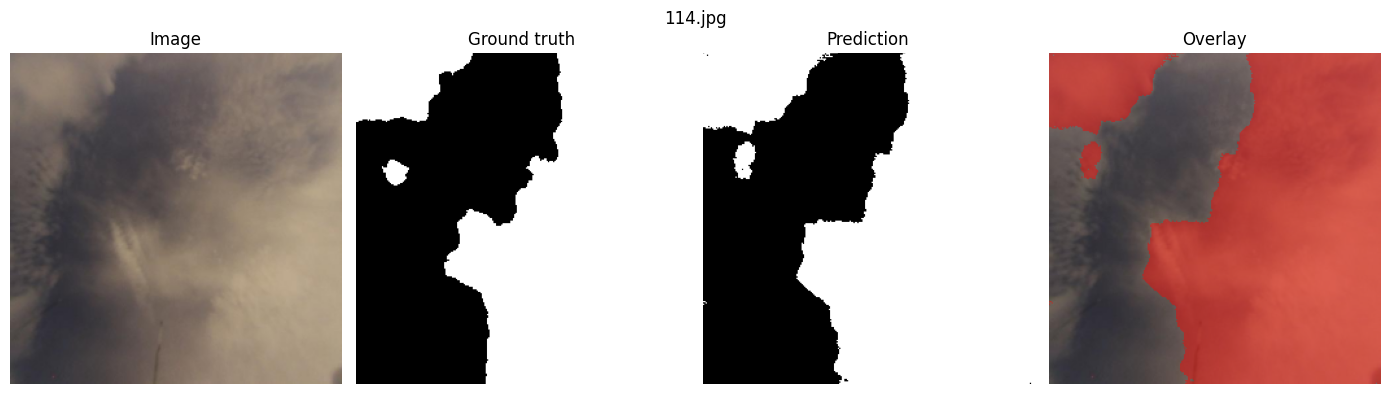

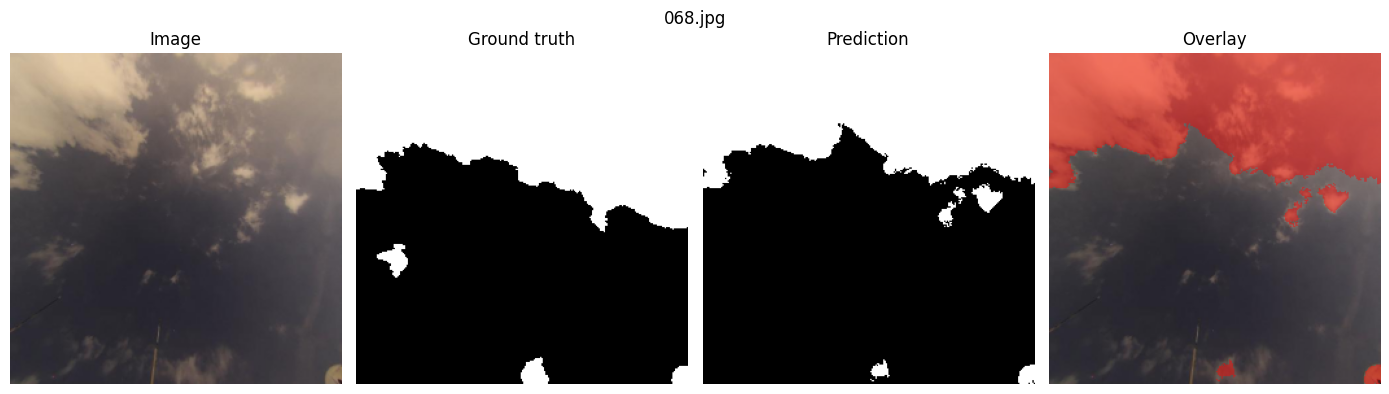

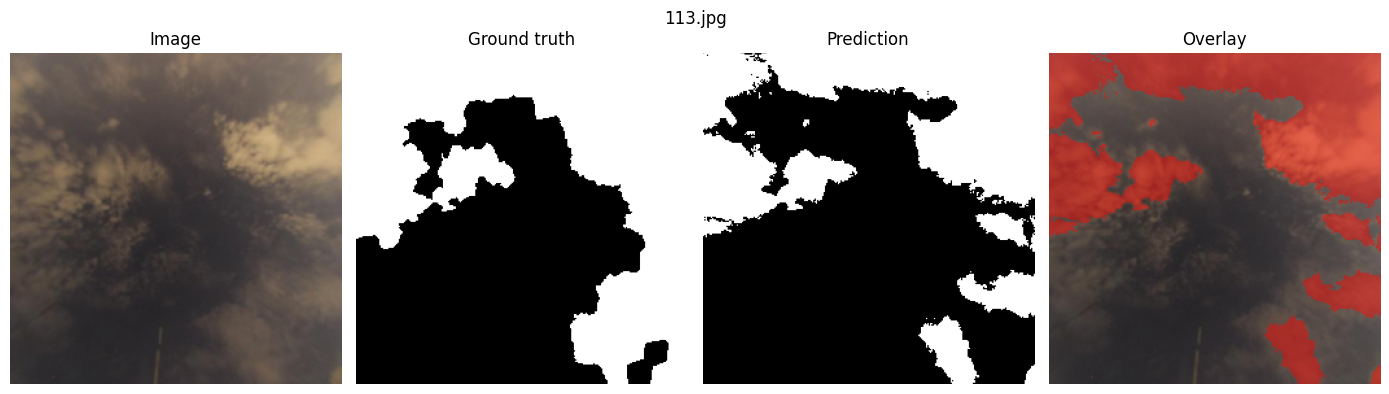

Per-image metrics: /content/resunet_swinseg_mod3_learnablekernel_outputs/test_metrics_per_image.csv
Summary metrics: /content/resunet_swinseg_mod3_learnablekernel_outputs/test_metrics_summary.csv
Predicted masks: /content/resunet_swinseg_mod3_learnablekernel_outputs/test_predicted_masks
Comparison previews: /content/resunet_swinseg_mod3_learnablekernel_outputs/test_previews

Saved 18 held-out test masks to: /content/resunet_swinseg_mod3_learnablekernel_outputs/test_predicted_masks
Dataset split manifest: /content/resunet_swinseg_mod3_learnablekernel_outputs/dataset_split_manifest.csv


In [6]:
METRIC_COLUMNS = ['IoU', 'Recall', 'Precision', 'Dice_Coefficient', 'Boundary_F1', 'Boundary_Recall', 'Boundary_Precision']

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, tp + fp + fn)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    contour_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_boundary = (gt_u8 - cv2.erode(gt_u8, contour_kernel, iterations=1)).astype(bool)
    pred_boundary = (pred_u8 - cv2.erode(pred_u8, contour_kernel, iterations=1)).astype(bool)
    tolerance_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (tolerance_size, tolerance_size))
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    boundary_precision = safe_divide(int(np.logical_and(pred_boundary, gt_dilated).sum()), int(pred_boundary.sum()))
    boundary_recall = safe_divide(int(np.logical_and(gt_boundary, pred_dilated).sum()), int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall, boundary_precision + boundary_recall)
    return {'IoU': iou, 'Recall': recall, 'Precision': precision, 'Dice_Coefficient': dice, 'Boundary_F1': boundary_f1, 'Boundary_Recall': boundary_recall, 'Boundary_Precision': boundary_precision}

def evaluate_split(split_name, split_pairs):
    mask_dir = os.path.join(OUTPUT_DIR, f'{split_name}_predicted_masks')
    preview_dir = os.path.join(OUTPUT_DIR, f'{split_name}_previews')
    os.makedirs(mask_dir, exist_ok=True)
    os.makedirs(preview_dir, exist_ok=True)
    for stale_file in list(Path(mask_dir).glob('*.png')) + list(Path(preview_dir).glob('*.png')):
        stale_file.unlink()
    rows = []
    preview_items = []
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        probabilities = tf.math.sigmoid(logits).numpy()
        pred_mask = probabilities >= PREDICTION_THRESHOLD
        gt_binary = gt_mask[..., 0] >= 0.5
        metrics = binary_segmentation_metrics(gt_binary, pred_mask)
        image_name = Path(image_path).name
        stem = Path(image_path).stem
        rows.append({'image_name': image_name, **metrics})
        pred_u8 = pred_mask.astype(np.uint8) * 255
        prediction_path = os.path.join(mask_dir, f'{stem}_prediction.png')
        if not cv2.imwrite(prediction_path, pred_u8):
            raise IOError(f'Could not save predicted mask: {prediction_path}')
        overlay = image.copy()
        overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
        if len(preview_items) < 4:
            preview_items.append((image_name, image, gt_binary, pred_mask, overlay))
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        axes[0].imshow(image)
        axes[0].set_title('Image')
        axes[1].imshow(gt_binary, cmap='gray')
        axes[1].set_title('Ground truth')
        axes[2].imshow(pred_mask, cmap='gray')
        axes[2].set_title('Prediction')
        axes[3].imshow(np.clip(overlay, 0, 1))
        axes[3].set_title('Overlay')
        for ax in axes:
            ax.axis('off')
        fig.suptitle(image_name)
        plt.tight_layout()
        preview_path = os.path.join(preview_dir, f'{stem}_comparison.png')
        fig.savefig(preview_path, dpi=140, bbox_inches='tight')
        plt.close(fig)
        print(f'{split_name.title()} {index}/{len(split_pairs)}: {image_name}')
    if len(rows) != len(split_pairs):
        raise RuntimeError(f'{split_name} evaluation did not process every sample.')
    if len(list(Path(mask_dir).glob('*.png'))) != len(split_pairs):
        raise RuntimeError(f'{split_name} predicted-mask count does not match its sample count.')
    results_df = pd.DataFrame(rows)
    per_image_csv = os.path.join(OUTPUT_DIR, f'{split_name}_metrics_per_image.csv')
    summary_csv = os.path.join(OUTPUT_DIR, f'{split_name}_metrics_summary.csv')
    results_df.to_csv(per_image_csv, index=False)
    summary_df = pd.DataFrame([{'metric': metric, 'macro_average': float(results_df[metric].mean()), 'std': float(results_df[metric].std(ddof=1)) if len(results_df) > 1 else 0.0, 'n_images': len(results_df)} for metric in METRIC_COLUMNS])
    summary_df.to_csv(summary_csv, index=False)
    print(f'\n{split_name.upper()} macro-average metrics')
    for _, row in summary_df.iterrows():
        print(f"{row['metric']:<22}: {row['macro_average']:.4f} ± {row['std']:.4f}")
    plt.figure(figsize=(12, 6))
    bars = plt.bar(summary_df['metric'], summary_df['macro_average'])
    plt.ylim(0, 1.05)
    plt.ylabel('Macro-average score')
    plt.title(f'ResUNET Modification 3 - {split_name.title()} metrics')
    plt.xticks(rotation=30, ha='right')
    plt.grid(axis='y', alpha=0.25)
    for bar, value in zip(bars, summary_df['macro_average']):
        plt.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f'{value:.3f}', ha='center', va='bottom', fontsize=9)
    plt.tight_layout()
    metric_plot = os.path.join(OUTPUT_DIR, f'{split_name}_metrics_summary.png')
    plt.savefig(metric_plot, dpi=160, bbox_inches='tight')
    plt.show()
    for image_name, image, gt, pred, overlay in preview_items:
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        axes[0].imshow(image)
        axes[0].set_title('Image')
        axes[1].imshow(gt, cmap='gray')
        axes[1].set_title('Ground truth')
        axes[2].imshow(pred, cmap='gray')
        axes[2].set_title('Prediction')
        axes[3].imshow(np.clip(overlay, 0, 1))
        axes[3].set_title('Overlay')
        fig.suptitle(image_name)
        for ax in axes:
            ax.axis('off')
        plt.tight_layout()
        plt.show()
    print('Per-image metrics:', per_image_csv)
    print('Summary metrics:', summary_csv)
    print('Predicted masks:', mask_dir)
    print('Comparison previews:', preview_dir)
    return results_df, summary_df

validation_results, validation_summary = evaluate_split('validation', val_pairs)
test_results, test_summary = evaluate_split('test', test_pairs)
print(f'\nSaved {len(test_pairs)} held-out test masks to: {os.path.join(OUTPUT_DIR, "test_predicted_masks")}')
print('Dataset split manifest:', os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv'))